# 第7章　ベイズ最適化の実践上の課題

材料試験を使って、入力の単位、観測ノイズ、獲得関数ソルバーの初期点、バッチの選び方を個別に調べます。図の数値は各セルが作る合成実験の結果です。比較ごとに固定するものを確認してください。

In [1]:
import json
import warnings
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import torch
from botorch.acquisition.analytic import LogExpectedImprovement, PosteriorMean
from botorch.acquisition.logei import qLogExpectedImprovement, qLogNoisyExpectedImprovement
from botorch.exceptions.warnings import InputDataWarning
from botorch.models.transforms.input import Normalize
from botorch.models.transforms.outcome import Standardize
from botorch.optim import optimize_acqf_discrete
from botorch.sampling.normal import SobolQMCNormalSampler
from robotorchan.models import SingleTaskGP
from robotorchan.optim import optimize_acqf
from torch.quasirandom import SobolEngine

from experiment import (
    BLUE, DTYPE, GREEN, ORANGE, QUALITY, SEED,
    fit_material_gp, material_strength, observations, save_figure, setup,
)

setup()
seeds = list(range(SEED, SEED + 20))
bounds_2d = torch.tensor([[140.0, 0.0], [180.0, 0.01]], dtype=DTYPE)

def physical(unit):
    return bounds_2d[0] + unit * (bounds_2d[1] - bounds_2d[0])

def strength_2d(unit):
    x, z = unit[:, :1], unit[:, 1:]
    target_fraction = 0.25 + 0.50 * x
    return material_strength(x) - 24 * (z - target_fraction).square()

test_unit = SobolEngine(2, scramble=True, seed=41).draw_base2(8).to(DTYPE)
test_true = strength_2d(test_unit)
rows = []
for seed in seeds:
    unit = SobolEngine(2, scramble=True, seed=seed).draw_base2(3).to(DTYPE)
    train_x = physical(unit)
    train_y = strength_2d(unit)
    train_var = torch.full_like(train_y, 0.01)
    row = {"seed": seed}
    for label, transform in (
        ("physical", None), ("normalized", Normalize(d=2, bounds=bounds_2d)),
    ):
        # 生の物理座標は比較のために渡す。意図した入力スケーリング警告だけ記録する。
        with warnings.catch_warnings(record=True) as seen:
            warnings.simplefilter("always", InputDataWarning)
            model = SingleTaskGP(
                train_x, train_y, train_Yvar=train_var,
                input_transform=transform, outcome_transform=Standardize(m=1),
            )
            model.fit()
        for warning in seen:
            expected = (label == "physical" and issubclass(warning.category, InputDataWarning)
                        and "unit cube" in str(warning.message))
            if not expected:
                warnings.warn(str(warning.message), warning.category)
        with torch.no_grad():
            pred = model.posterior(physical(test_unit)).mean
            row[label] = (pred - test_true).square().mean().sqrt().item()
    rows.append(row)
print("共通検証点のRMSE [MPa]:", rows)

共通検証点のRMSE [MPa]: [{'seed': 2026, 'physical': 7.828160961706793, 'normalized': 2.6860292665108405}, {'seed': 2027, 'physical': 7.596694821652854, 'normalized': 4.683879454725322}, {'seed': 2028, 'physical': 7.813094995120459, 'normalized': 4.945620769003989}, {'seed': 2029, 'physical': 7.873093439992496, 'normalized': 4.043384871289533}, {'seed': 2030, 'physical': 7.643679911067733, 'normalized': 3.5155935733915764}, {'seed': 2031, 'physical': 8.077368846798601, 'normalized': 4.356824538571704}, {'seed': 2032, 'physical': 7.733279299265234, 'normalized': 2.6791347589919896}, {'seed': 2033, 'physical': 7.621233754585662, 'normalized': 3.938288498403557}, {'seed': 2034, 'physical': 7.682883176389219, 'normalized': 3.2018110707298644}, {'seed': 2035, 'physical': 7.805546217382967, 'normalized': 4.041972234526515}, {'seed': 2036, 'physical': 7.662533483076183, 'normalized': 3.4000340217241334}, {'seed': 2037, 'physical': 7.784594423880167, 'normalized': 3.8426239642460387}, {'seed': 2038, 

## 7.1 入力だけを変えた比較

温度 $T$ と添加比 $r$ をそれぞれ1列で扱います。入力はどちらのモデルにも物理単位で渡し、正規化するモデルだけが内部で変換します。両モデルの出力変換は同じです。保留した共通の256点で誤差を測ります。

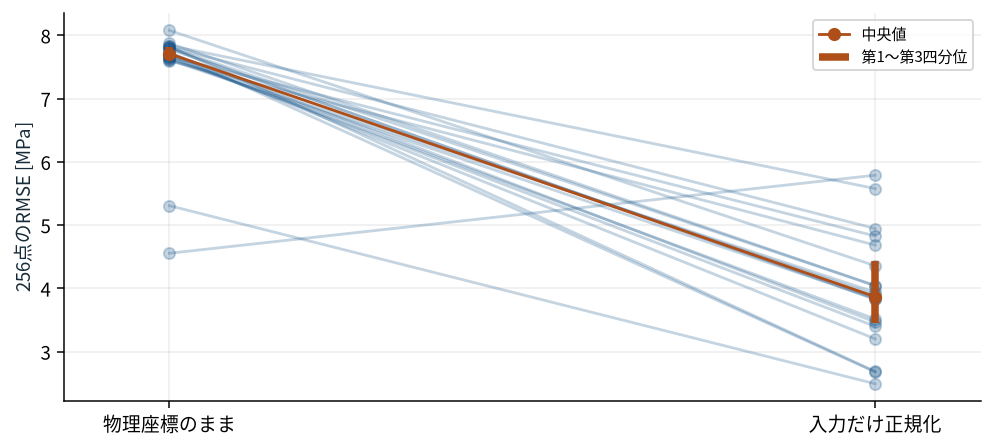

In [2]:
fig, ax = plt.subplots(figsize=(7.25, 3.2), layout="constrained")
for row in rows:
    ax.plot([0, 1], [row["physical"], row["normalized"]], "o-", alpha=0.25, color=BLUE)
summaries = np.quantile([[row[key] for row in rows] for key in ("physical", "normalized")],
                        [0.25, 0.5, 0.75], axis=1)
ax.plot([0, 1], summaries[1], "o-", color=ORANGE, label="中央値")
ax.vlines([0, 1], summaries[0], summaries[2], color=ORANGE, lw=4, label="第1〜第3四分位")
ax.set(xticks=[0, 1], xticklabels=["物理座標のまま", "入力だけ正規化"],
       ylabel="256点のRMSE [MPa]")
ax.set_xlim(-0.15, 1.15)
ax.legend(fontsize=8)
save_figure(fig, "ch07_scaling")

## 7.2 測定ノイズと改善の基準

41候補を使う決定論的な潜在強度は全条件で共通です。各seedで同じ温度には同じ誤差を割り当てます。初期4点と追加4点を揃え、①ノイズなし解析LogEI、②ノイズあり解析LogEI、③ノイズありqLogNEIを比較します。学習に使う値は測定値です。真値は探索を終えた後の診断に使います。

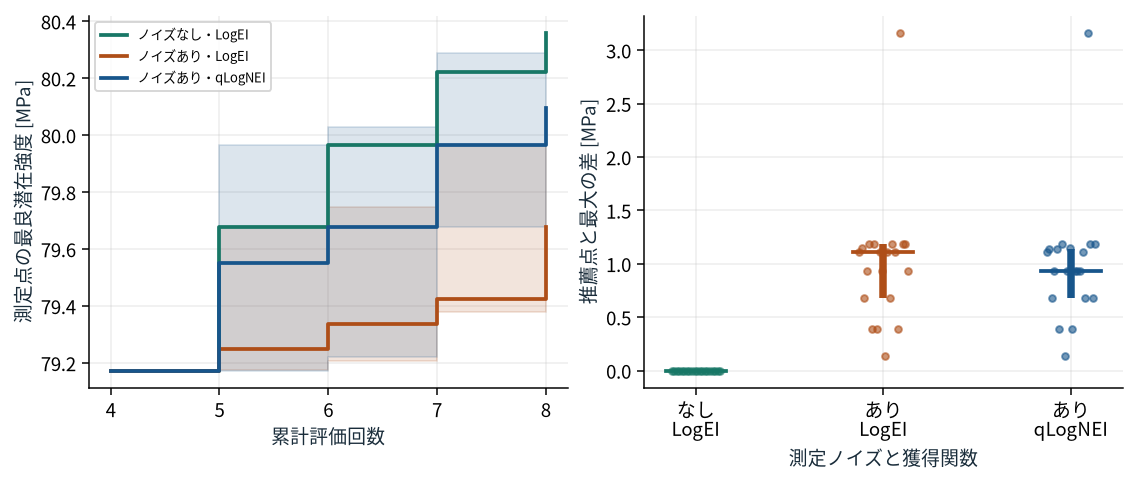

In [3]:
pool = torch.linspace(0, 1, 41, dtype=DTYPE).unsqueeze(-1)
initial = torch.tensor([2, 9, 20, 34])
cases = (
    ("clean_logei", "ノイズなし・LogEI", 0.0, False),
    ("noisy_logei", "ノイズあり・LogEI", 2.0, False),
    ("noisy_lognei", "ノイズあり・qLogNEI", 2.0, True),
)
noise_rows = []
for seed in seeds:
    generator = torch.Generator().manual_seed(seed)
    errors = torch.randn(len(pool), 1, dtype=DTYPE, generator=generator)
    for key, label, noise_sd, noise_aware in cases:
        indices = initial.tolist()
        train_y = material_strength(pool[initial]) + noise_sd * errors[initial]
        candidate_time = 0.0
        for step in range(4):
            train_x = pool[indices]
            train_var = torch.full_like(train_y, max(0.01, noise_sd**2))
            model = fit_material_gp(train_x, train_y, train_var)
            if noise_aware:
                sampler = SobolQMCNormalSampler(torch.Size([64]), seed=seed + step)
                acquisition = qLogNoisyExpectedImprovement(
                    model, X_baseline=train_x, sampler=sampler, prune_baseline=False,
                )
            else:
                acquisition = LogExpectedImprovement(model, best_f=train_y.max())
            available = torch.ones(len(pool), dtype=torch.bool)
            available[indices] = False
            start = perf_counter()
            point, _ = optimize_acqf_discrete(acquisition, q=1, choices=pool[available])
            candidate_time += perf_counter() - start
            index = int((pool - point).abs().argmin())
            assert index not in indices
            indices.append(index)
            value = material_strength(point) + noise_sd * errors[index:index+1]
            train_y = torch.cat((train_y, value))
        assert len(indices) == len(set(indices)) == 8 and indices[:4] == initial.tolist()

        # 診断用。未測定点の真値を選択に渡さず、最後に合成実験の成績を比較する。
        fitted = fit_material_gp(pool[indices], train_y,
                                 torch.full_like(train_y, max(0.01, noise_sd**2)))
        with torch.no_grad():
            chosen = int(fitted.posterior(pool[indices]).mean[:, 0].argmax())
        optimum = material_strength(pool).max().item()
        latent_y = material_strength(pool[indices])[:, 0]
        noise_rows.append({
            "seed": seed, "case": key, "evaluation_count": len(indices),
            "best_observed_mpa": train_y.max().item(),
            "latent_best_path_mpa": latent_y.cummax(0).values.tolist(),
            "recommendation_gap_mpa": optimum - latent_y[chosen].item(),
            "candidate_seconds": candidate_time,
        })

fig, (ax, bx) = plt.subplots(1, 2, figsize=(8.3, 3.45), layout="constrained")
for index, ((key, label, _, _), color) in enumerate(zip(cases, (GREEN, ORANGE, BLUE))):
    selected = [row for row in noise_rows if row["case"] == key]
    paths = np.asarray([row["latent_best_path_mpa"] for row in selected])
    x = list(range(4, 9))
    q1, med, q3 = np.quantile(paths[:, 3:], [0.25, 0.5, 0.75], axis=0)
    ax.fill_between(x, q1, q3, step="post", color=color, alpha=0.15)
    ax.step(x, med, where="post", color=color, linewidth=2.0, label=label)
    gaps = [row["recommendation_gap_mpa"] for row in selected]
    bx.scatter(np.linspace(index-0.13, index+0.13, len(gaps)), gaps, color=color, alpha=0.6, s=13)
    q1, med, q3 = np.quantile(gaps, [0.25, 0.5, 0.75])
    bx.vlines(index, q1, q3, color=color, lw=4)
    bx.plot([index-0.16, index+0.16], [med]*2, color=color, linewidth=2)
ax.set(xlabel="累計評価回数", ylabel="測定点の最良潜在強度 [MPa]", xticks=list(range(4, 9)))
ax.legend(fontsize=7)
bx.set(xticks=[0, 1, 2], xticklabels=["なし\nLogEI", "あり\nLogEI", "あり\nqLogNEI"],
       ylabel="推薦点と最大の差 [MPa]", xlabel="測定ノイズと獲得関数")
save_figure(fig, "ch07_measurement_noise")

## 7.4 連続最適化が止まる場所を調べる

第4・5章の共通データでGPを固定し、解析LogEIを最適化します。ソルバーと範囲を固定し、初期候補を1点だけ与える場合と5点与える場合を比較します。描画グリッドは診断の目安に使います。

[{'label': '初期点1個', 'x': 0.0, 'score': -4.4177918663447, 'seconds': 0.012870836999979929}, {'label': '初期点5個', 'x': 0.3017034440305781, 'score': -0.2538200921600503, 'seconds': 0.035120939000023554}]


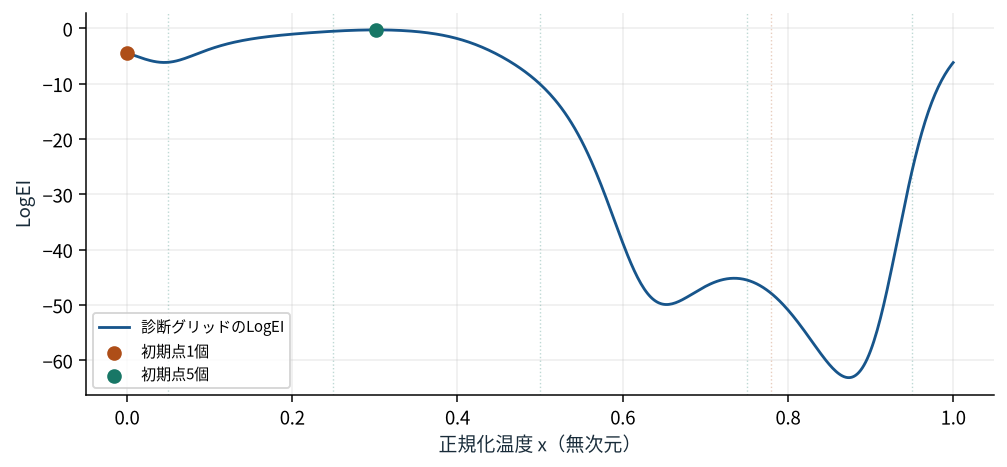

In [4]:
train_x, train_y, train_yvar = observations()
model = fit_material_gp(train_x, train_y, train_yvar)
acq = LogExpectedImprovement(model, best_f=train_y.max())
bounds = torch.tensor([[0.0], [1.0]], dtype=DTYPE)
grid = torch.linspace(0, 1, 501, dtype=DTYPE).reshape(-1, 1, 1)
with torch.no_grad():
    values = acq(grid)

starts = [[0.78], [0.05, 0.25, 0.5, 0.75, 0.95]]
local_rows = []
fig, ax = plt.subplots(figsize=(7.35, 3.35), layout="constrained")
ax.plot(grid[:, 0, 0], values, color=BLUE, label="診断グリッドのLogEI")
for positions, label, color in zip(starts, ("初期点1個", "初期点5個"), (ORANGE, GREEN)):
    x0 = torch.tensor(positions, dtype=DTYPE).reshape(-1, 1, 1)
    t = perf_counter()
    candidate, score = optimize_acqf(
        acq, bounds, q=1, num_restarts=len(x0), raw_samples=None,
        batch_initial_conditions=x0,
    )
    local_rows.append({"label": label, "x": candidate.item(), "score": score.item(),
                       "seconds": perf_counter() - t})
    ax.scatter(candidate, score, s=46, color=color, zorder=4, label=label)
    for x in positions:
        ax.axvline(x, color=color, alpha=0.28, linewidth=0.75, linestyle=":")
ax.set(xlabel="正規化温度 x（無次元）", ylabel="LogEI")
ax.legend(fontsize=8)
save_figure(fig, "ch07_solver_starts")
print(local_rows)

## 7.5 2点を同時に選ぶ

同じモデルとqLogEIで、2点を同時に最適化する方法と、一方を保留点にしてもう一方を選ぶ逐次貪欲法を実行します。両方法で目的関数の評価を行うなら2点分です。図の点を同じ獲得関数で再評価して、2点の組として比較します。

2点をまとめて再評価: [{'label': '同時', 'x': [0.22748325815725415, 0.3199310847155038], 'score': -0.06045571411801909, 'seconds': 0.0879521479999994}, {'label': '逐次貪欲', 'x': [0.20863135522888435, 0.3016942962874316], 'score': -0.08424359455050023, 'seconds': 0.10431611499996052}]


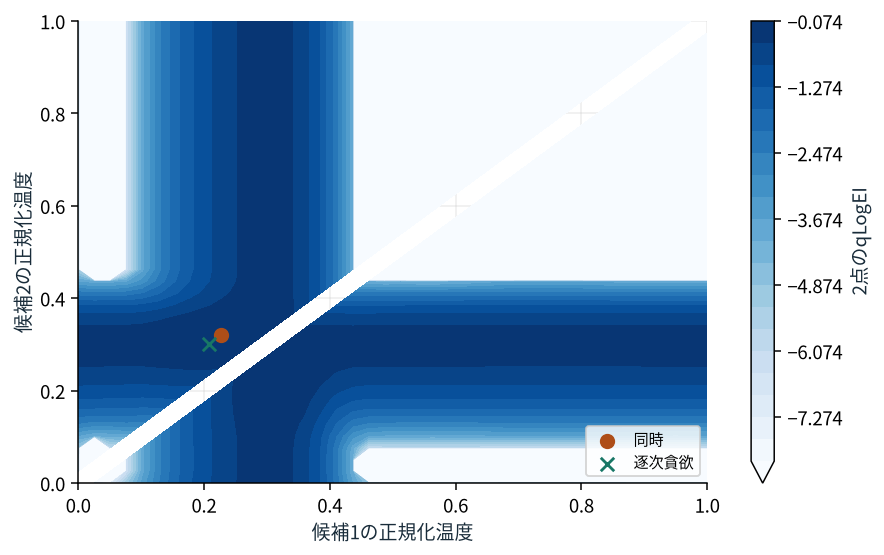

In [5]:
def batch_acquisition():
    return qLogExpectedImprovement(
        model, best_f=train_y.max(),
        sampler=SobolQMCNormalSampler(torch.Size([128]), seed=SEED),
    )

batch_rows = []
reference_acq = batch_acquisition()
for sequential, label in ((False, "同時"), (True, "逐次貪欲")):
    source = batch_acquisition()
    start = perf_counter()
    batch, _ = optimize_acqf(
        source, bounds, q=2, sequential=sequential, num_restarts=6, raw_samples=96,
        options={"seed": SEED},
    )
    elapsed = perf_counter() - start
    assert batch.shape == (2, 1) and (batch >= 0).all() and (batch <= 1).all()
    ordered = batch[:, 0].sort().values
    with torch.no_grad():
        score = reference_acq(ordered.reshape(1, 2, 1)).item()
    assert np.isfinite(score)
    batch_rows.append({"label": label, "x": ordered.tolist(), "score": score, "seconds": elapsed})

axis = torch.linspace(0, 1, 40, dtype=DTYPE)
first, second = torch.meshgrid(axis, axis, indexing="xy")
pairs = torch.stack((first.flatten(), second.flatten()), dim=1).unsqueeze(-1)
# 診断図の対角では入力が重複するため、異なる2温度の組だけ評価する。
distinct = first.flatten() != second.flatten()
joint_scores = torch.full((40 * 40,), torch.nan, dtype=DTYPE)
with torch.no_grad():
    joint_scores[distinct] = reference_acq(pairs[distinct])
joint_scores = joint_scores.reshape(40, 40)
fig, ax = plt.subplots(figsize=(6.45, 4), layout="constrained")
peak = joint_scores[torch.isfinite(joint_scores)].max().item()
levels = np.linspace(peak - 8, peak, 21)
heat = ax.contourf(first, second, joint_scores, levels=levels, cmap="Blues", extend="min")
for row, color, marker in zip(batch_rows, (ORANGE, GREEN), ("o", "x")):
    ax.scatter(*row["x"], color=color, s=51, marker=marker, label=row["label"], zorder=4)
ax.set(xlabel="候補1の正規化温度", ylabel="候補2の正規化温度")
ax.legend(fontsize=8, loc="lower right")
fig.colorbar(heat, ax=ax, label="2点のqLogEI")
save_figure(fig, "ch07_batch_selection")

metrics = {
    "seeds": seeds, "scaling": rows, "noise": noise_rows, "solver_starts": local_rows,
    "diagnostic_grid_max_x": grid[values.argmax(), 0, 0].item(),
    "batch": batch_rows,
}
(QUALITY / "ch07_metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print("2点をまとめて再評価:", batch_rows)

## 章末演習
1. **確認。** 第7.1節で同じにした項目を挙げ、物理座標と内部の正規化座標の関係を書きましょう。
2. **操作。** 測定ノイズの標準偏差を2 MPaから4 MPaに変え、各方法の推薦点の差と最良観測値を調べます。4つのseed・初期4点・追加4点を維持します。
3. **発展。** 2台の装置が同時に測れる場合と、片方が先に終わる場合に、評価回数と終了時刻をどのように比較するかを説明しましょう。